<center><h1>Linarez_Isabella_HW7</h1></center>

Name: Isabella Linarez
<br>
Github Username: isalinarez927
<br>
USC ID: 7543590784

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline  

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, hamming_loss

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=UserWarning)

### (a) Download the Anuran Calls (MFCCs) Data Set

In [18]:
df = pd.read_csv("data/Frogs_MFCCs.csv")

X = df.filter(like="MFCC")
Y = df[["Family", "Genus", "Species"]]

X_train, X_test, Y_train, Y_test = train_test_split( X, Y, test_size=0.3, random_state=RANDOM_STATE )

### (b) Train a classifier for each label

#### (i) Research

- Exact Match Ratio: Measures the percentage of samples where every single predicted label matches the true label set. It is a very strict metric because one wrong label marks the entire sample as incorrect.
- Hamming Score: the fraction of individual labels predicted correctly across all samples, which is 1 − Hamming Loss. It gives partial credit when only some of a sample's labels are correct
- Hamming Loss: Measures the fraction of total individual labels that are predicted FALSE across all samples and classes. A score near 0 suggests better overall model performance.


#### (ii) Train a SVM for each of the labels

In [19]:
def eval_svm(X_train, Y_train, X_test, Y_test):
    labels = ["Family", "Genus", "Species"]
    best_params = {}
    Y_pred = pd.DataFrame(index=Y_test.index, columns=labels)        

    C_range = [1, 10, 100, 1000]
    sigma_range = np.array([0.2, 0.3, 0.4, 0.5, 1.0])
    gamma_range = 1.0 / (2.0 * sigma_range**2)
    param_grid = {"svm__estimator__C": C_range, "svm__estimator__gamma": gamma_range}

    steps = [("svm", OneVsRestClassifier(SVC(kernel="rbf")))]           
    pipe = Pipeline(steps)

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)  

    for label in labels:                                                
        grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
        grid.fit(X_train, Y_train[label])                              
        best_params[label] = grid.best_params_
        Y_pred[label] = grid.predict(X_test)

    ytnp = Y_test.to_numpy()
    ypnp = Y_pred.to_numpy()
    exact_match = np.mean(np.all(ypnp == ytnp, axis=1))  
    h_loss = np.mean(ytnp != ypnp)                       
    hamming_score = 1 - h_loss

    print(f"Exact Match Ratio: {exact_match:.4f}")
    print(f"Hamming Score:     {hamming_score:.4f}")
    print(f"Hamming Loss:      {h_loss:.4f}")
    for label in labels:
        print(f" - {label}: {best_params[label]}")

    return Y_pred, best_params

In [20]:
Y_pred_raw, params_raw = eval_svm(X_train, Y_train, X_test, Y_test)

Exact Match Ratio: 0.9893
Hamming Score:     0.9924
Hamming Loss:      0.0076
 - Family: {'svm__estimator__C': 100, 'svm__estimator__gamma': np.float64(3.1249999999999996)}
 - Genus: {'svm__estimator__C': 10, 'svm__estimator__gamma': np.float64(3.1249999999999996)}
 - Species: {'svm__estimator__C': 10, 'svm__estimator__gamma': np.float64(3.1249999999999996)}


The first grid's best gamma was at sigma = 0.5 (upper edge), so the sigma range was extended to smaller values. The extended grid selected sigma = 0.4 (gamma ≈ 3.125) for the three labels. This is an interior value, so the optimal value is within the search range.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [21]:
def eval_l1_svm(X_train, Y_train, X_test, Y_test, with_smote=False):
    labels = ["Family", "Genus", "Species"]
    best_params = {}
    Y_pred = pd.DataFrame(index=Y_test.index, columns=labels)

    param_grid = {"svm__C": np.logspace(-3, 3, 7)} 

    steps = [("scaler", StandardScaler())]         
    if with_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("svm", LinearSVC(penalty="l1", dual=False, max_iter=5000)))
    pipe = ImbPipeline(steps)

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

    for label in labels:
        grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
        grid.fit(X_train, Y_train[label])
        best_params[label] = grid.best_params_
        Y_pred[label] = grid.predict(X_test)

    ytnp = Y_test.to_numpy()
    ypnp = Y_pred.to_numpy()
    exact_match = np.mean(np.all(ypnp == ytnp, axis=1))  
    h_loss = np.mean(ytnp != ypnp)                       
    hamming_score = 1 - h_loss

    print(f"Exact Match Ratio: {exact_match:.4f}")
    print(f"Hamming Score:     {hamming_score:.4f}")
    print(f"Hamming Loss:      {h_loss:.4f}")
    for label in labels:
        print(f" - {label}: {best_params[label]}")

    return Y_pred, best_params

In [22]:
print("L1-Penalized")
Y_pred_l1, params_l1 = eval_l1_svm(X_train, Y_train, X_test, Y_test)

L1-Penalized
Exact Match Ratio: 0.9125
Hamming Score:     0.9430
Hamming Loss:      0.0570
 - Family: {'svm__C': np.float64(10.0)}
 - Genus: {'svm__C': np.float64(1000.0)}
 - Species: {'svm__C': np.float64(10.0)}


the selected C = 1000 for Genus is at the upper edge of the grid, so a larger C might score slightly better. At this size the L1 penalty is already very weak so the gains are probaly small

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [23]:
print("L1 with SMOTE")
Y_pred_smote, params_smote = eval_l1_svm(X_train, Y_train, X_test, Y_test, with_smote=True)

L1 with SMOTE
Exact Match Ratio: 0.8536
Hamming Score:     0.9231
Hamming Loss:      0.0769
 - Family: {'svm__C': np.float64(10.0)}
 - Genus: {'svm__C': np.float64(1.0)}
 - Species: {'svm__C': np.float64(10.0)}


| Model | Exact Match | Hamming Score | Hamming Loss |
|---|---|---|---|
| Gaussian (RBF) SVM | 0.9893 | 0.9924 | 0.0076 |
| L1-penalized SVM | 0.9125 | 0.9430 | 0.0570 |
| L1 SVM + SMOTE | 0.8536 | 0.9231 | 0.0769 |

**Conclusions:** 
- Gaussian-kernel SVM performed best probably bc nonlinear boundaries fit the data better than the linear boundaries of the L1 SVM. 
- SMOTE did not help. it shifted the classifier's focus  toward the rare classes.  So it reduces accuracy on the common classes that dominate the imbalanced test set
- all three metrics got worse

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

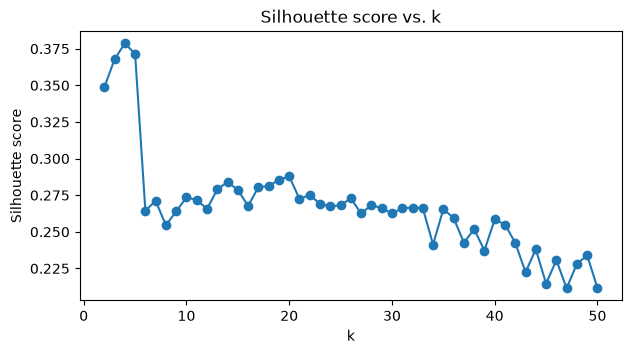

Best k: 4


In [24]:
k_values = list(range(2, 51))
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_labels = km.fit_predict(X)
    silhouette_scores.append(
        silhouette_score(X, cluster_labels)
    )

plt.figure(figsize=(7, 3.5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.title("Silhouette score vs. k")
plt.show()

best_k = k_values[int(np.argmax(silhouette_scores))]
print("Best k:", best_k)

NOTE: Silhouette needs at least two clusters to compare against, so $k = 1$ can’t be scored, even though the homework’s range starts at 1

### (b) Determine which family is the majority

In [25]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
clusters = km.fit_predict(X)

labels = ["Family", "Genus", "Species"]
Y_clust = pd.DataFrame(index=Y.index)
majority_dict = {}

for label in labels:
    m = {}                                          
    for c in np.unique(clusters):                   
        in_c = Y[label][clusters == c]              
        m[c] = in_c.value_counts().idxmax() 
    majority_dict[label] = m
    Y_clust[label] = pd.Series(clusters, index=Y.index).map(m)

print("Majority per cluster:")
print(pd.DataFrame(majority_dict))

Majority per cluster:
            Family      Genus                 Species
0  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1          Hylidae  Hypsiboas    HypsiboasCinerascens
2    Dendrobatidae   Ameerega      Ameeregatrivittata
3          Hylidae  Hypsiboas       HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [26]:
true_labels = Y.to_numpy()
pred_labels = Y_clust.to_numpy()
wrong = np.not_equal(true_labels, pred_labels)

ham_dist  = wrong.sum(axis=1).mean()  
ham_loss  = wrong.mean()             
ham_score = 1 - ham_loss

print(f"Avg Hamming distance: {ham_dist:.4f}")
print(f"Hamming score:        {ham_score:.4f}")
print(f"Hamming loss:         {ham_loss:.4f}")

Avg Hamming distance: 0.6673
Hamming score:        0.7776
Hamming loss:         0.2224


NOTE: majority table has Hylidae twice and no Bufonidae, so with $k = 4$ one family is never predicted (explaining hamming loss)

### MONTE CARLO

In [27]:
n_runs = 50
ham_dists, ham_scores, ham_losses = [], [], []

labels = ["Family", "Genus", "Species"]

for run in range(n_runs):
    km = KMeans(n_clusters=best_k, n_init=10, random_state=run)
    clusters = km.fit_predict(X)

    Y_clust = pd.DataFrame(index=Y.index)
    for label in labels:
        m = {}
        for c in np.unique(clusters):
            m[c] = Y[label][clusters == c].value_counts().idxmax()
        Y_clust[label] = pd.Series(clusters, index=Y.index).map(m)

    wrong = Y.to_numpy() != Y_clust.to_numpy()
    ham_dists.append(wrong.sum(axis=1).mean())
    ham_losses.append(wrong.mean())
    ham_scores.append(1 - wrong.mean())

print(f"Over {n_runs} runs (k = {best_k}):")
print(f"Hamming distance: mean = {np.mean(ham_dists):.4f}, std = {np.std(ham_dists):.4f}")
print(f"Hamming score:    mean = {np.mean(ham_scores):.4f}, std = {np.std(ham_scores):.4f}")
print(f"Hamming loss:     mean = {np.mean(ham_losses):.4f}, std = {np.std(ham_losses):.4f}")

Over 50 runs (k = 4):
Hamming distance: mean = 0.6719, std = 0.0168
Hamming score:    mean = 0.7760, std = 0.0056
Hamming loss:     mean = 0.2240, std = 0.0056


- standard deviations are small, they are ≈0.017 for Hamming distance), so the k-means clustering with k = 4 is stable across random initializations. 
- the single run in 2(c) is representative.

## 3. ISLR 12.6.2

![ISLR 12.6.2](islr12.jpeg)
#### (c)
Cutting the complete linkage dendrogram between the last two merges at height .6, gives two clusters: {1,2} and {3,4}

#### (d)
Cutting the single linkage dendrogram between the last two merges at height .42, gives two clusters: {1,2,3} and {4}

#### (e)
<img src="islr12e.jpeg" width="300">


Swapping the branches at the 0.3 and 0.45 merges changes the leaf order from 1, 2, 3, 4 to 2, 1, 4, 3. Every fusion still joins the same clusters at the same heights ({1,2} at 0.3, {3,4} at 0.45, and everything at 0.8), so this dendrogram has the same meaning as the one in (a).